# Figure 6 | Snow density and temperature

Powder Patch Meteorological Station (PPSA), WY 2025. The default is the PPSA met mixed forcing run with lapse-rate-corrected HRRR-AK fill
and soil enabled, as used in the main [Figure 4 notebook](figure4_publication.ipynb). Edit the settings cell to change the
model run, figure window, sampling, or scales.

Dark gray dashed lines mark the model timestamps for the cold and warm pits selected in [Table 2](../../tables/table2_publication.ipynb). The timelines show simulated layers. To change the dates, run the
[publication selector](select_table2_snowpit.ipynb), then rerun this notebook.

[SNOWPACK PRO format and grain codes](https://snowpack.slf.ch/doc-dev/html/snowpackio.html) · [NiViz grain-color and crust conventions](https://niviz.org/niviz/dist/doc/files/lib_graphs_gradient.js.html)

In [5]:
from importlib import reload
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'figures/notebooks/snowpack_profiles.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Start the notebook from the manuscript repository.')
sys.path.insert(0, str(root / 'figures/notebooks'))

import snowpack_profiles

reload(snowpack_profiles)
from snowpack_profiles import plot_profiles, read_profiles, save_figure

In [6]:
model_root = Path('/home/cassie/python/models/run_snowpack/sites')
site = 'ppsa'
simulation = 'met_hrrrak_lapserate_ppsa_WY2020-WY2025_soil'
pro_path = model_root / site / 'output' / f'{simulation}.pro'
window = tuple(map(pd.Timestamp, ('2024-10-01', '2025-07-01')))
variables = ('density', 'temperature')
sample_hours = 3
depth_max = 250
color_limits = {}  # Set per-variable limits to override the NiViz-style scales.
output_dir = root / 'figures/files'


,pit_class,model_time
0,cold,2025-02-16 12:00:00
1,warm,2025-02-27 12:00:00


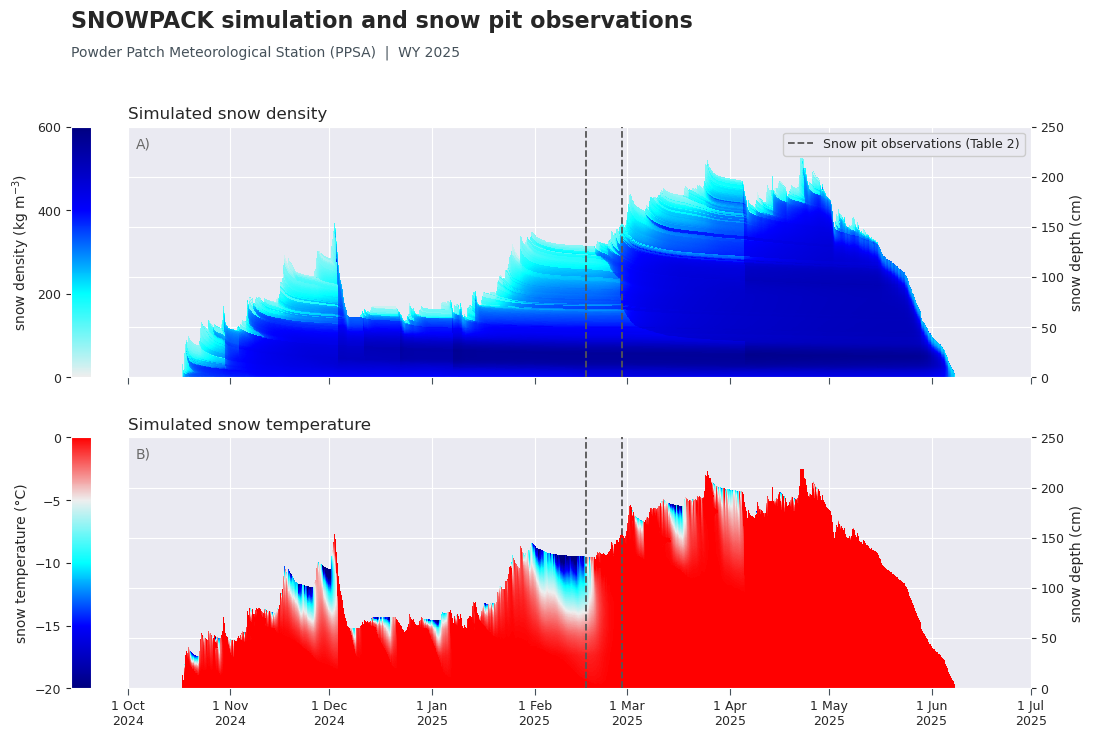

In [7]:
selection = snowpack_profiles.read_pit_selection(
    root / 'figures/data/ppsa_snowpit_selection_WY2025.csv', window)
pit_times = selection['model_time']
display(selection[['pit_class', 'model_time']])

profiles, cadence = read_profiles(pro_path, *window, variables, sample_hours=sample_hours)
fig = plot_profiles(profiles, cadence, variables, window,
                    heading='SNOWPACK simulation and snow pit observations',
                    subtitle='Powder Patch Meteorological Station (PPSA)  |  WY 2025',
                    depth_max=depth_max, color_limits=color_limits, pit_times=pit_times,
                    monthly_date_ticks=True, pit_line_color='#555555', timeline_hspace=0.24)
save_figure(fig, output_dir, 'figure6_publication')
plt.show()

## Figure 6 with Table 2 pit profiles

Panels C–F follow the ground-aligned layout in the [Table 2 profiles notebook](select_table2_snowpit.ipynb).
Each observed column is paired with a snapshot from the same simulation shown in the timelines,
at the exact timestamp of its dashed line. The density and temperature columns use the
corresponding color scales above. Density bands span the sampled intervals. Overlapping samples
are shown side by side. Temperature is interpolated between measured snow and surface readings.
Readings above 0 °C use the warmest color on the shared temperature scale.

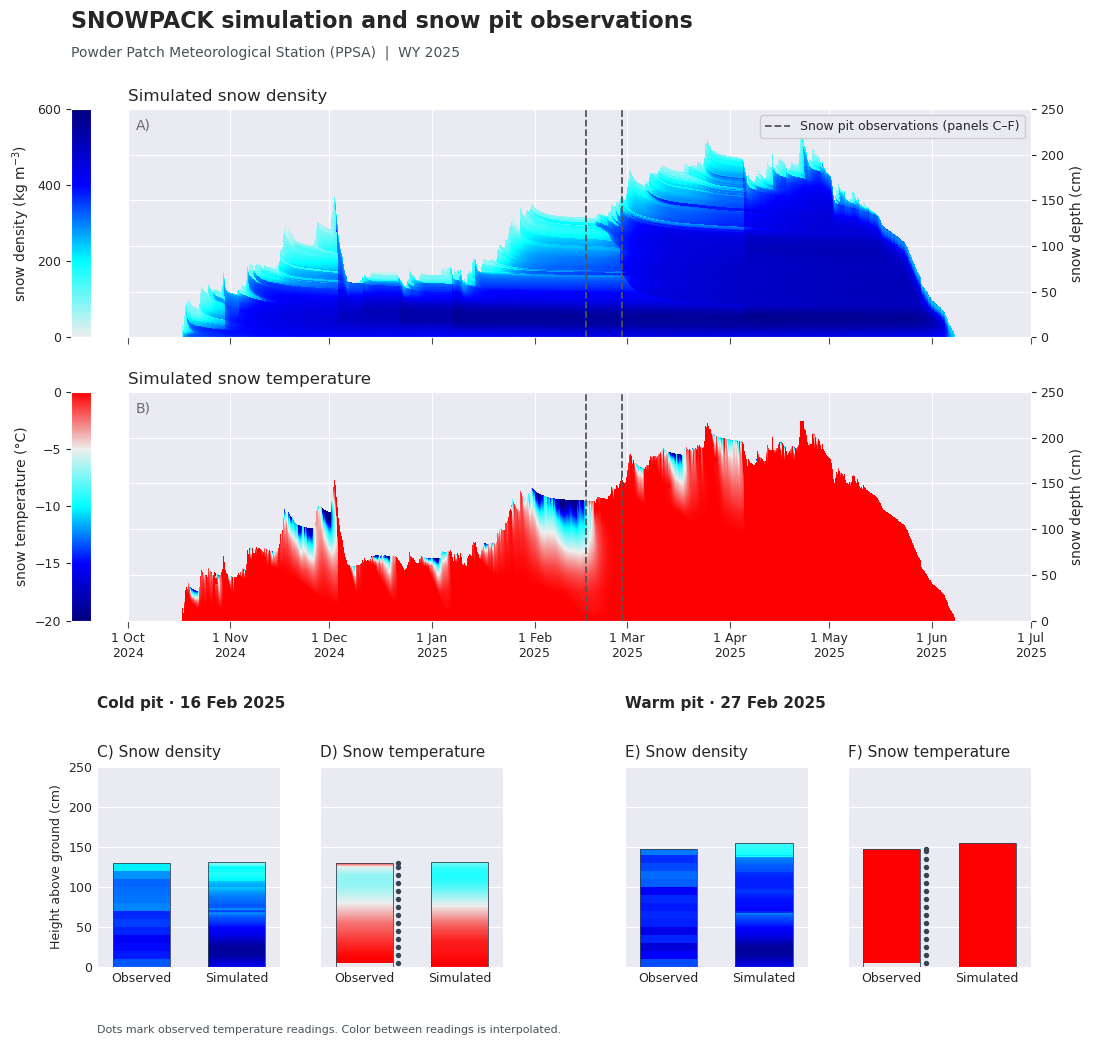

In [8]:
# Refresh the module even when this cell is rerun in a long-lived notebook kernel.
from importlib import reload
import snowpack_profiles

reload(snowpack_profiles)
selection = snowpack_profiles.read_pit_selection(
    root / 'figures/data/ppsa_snowpit_selection_WY2025.csv', window)
pit_times = selection['model_time']
field = pd.read_csv(root / 'figures/data/ppsa_snowpit_profiles_WY2025.csv',
                    parse_dates=['date'])
hourly, _ = read_profiles(pro_path, pit_times.min(), pit_times.max() + pd.Timedelta(seconds=1),
                          variables, sample_hours=1)
snapshots = {profile.time: profile for profile in hourly if len(profile.top_cm)}
comparisons = []
for pit in selection.itertuples(index=False):
    rows = field.loc[field['date'].eq(pit.date)]
    if rows.empty or pit.model_time not in snapshots:
        raise ValueError(f'Missing field data or exact snowy model profile for {pit.model_time}.')
    comparisons.append((f'{pit.pit_class.capitalize()} pit', pit.date,
                        rows, snapshots[pit.model_time]))

fig_with_pits = snowpack_profiles.plot_profiles(
    profiles, cadence, variables, window,
    heading='SNOWPACK simulation and snow pit observations',
    subtitle='Powder Patch Meteorological Station (PPSA)  |  WY 2025',
    depth_max=depth_max, color_limits=color_limits, pit_times=pit_times,
    pit_comparisons=comparisons,
    monthly_date_ticks=True, pit_line_color='#555555', timeline_hspace=0.24,
)
save_figure(fig_with_pits, output_dir, 'figure6_publication_with_pits')
plt.show()